# 阶段 1：把短信营销当作 A/B 实验来分析

1. 数据核对与质量检查（三张表）
2. 样本比例失衡检验（SRM）
3. 平衡性检验：客户信息 + 实验前的消费行为（也相当于安慰剂检验）
4. 平均处理效应（ATE）与显著性检验
5. CUPED：用实验前的消费降低方差；以及一个“用错协变量”的反面例子
6. 最小可检测效应（MDE）

官方页面没有说明短信是否随机发送，所以第 2、3 步是做因果结论的前提。

## 1.1 文件核对

In [1]:
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.abtest import cuped, diff_in_means, mde, ols_ate, srm_test
from src.balance import balance_table, expand_features, joint_balance_test
from src.config import RESULTS
from src.data import FILES, connect, load_clients, load_train, verify_files
from src.features import CUTOFF, client_basic, pre_period_metrics
from src.plotting import INK_SECONDARY, SERIES, setup_matplotlib, smd_plot

setup_matplotlib()
result = {}
files = verify_files()
result["files"] = {k: {"字节数": int(v[0]), "sha256": v[1]} for k, v in files.items()}
pd.DataFrame(result["files"]).T

,字节数,sha256
uplift_train,1182423,0a218e864a1ec1dfe26e980a082b81d5f46d199c4a6ae3...
clients,7637755,bfca1719b862735ae9816ed9bbba6924931c6a4dff761c...
purchases,669979268,3d57519fa92b553fd1e947c120add475cc42e0c64c323a...


## 1.2 实验标签表与客户信息表

In [2]:
train = load_train()
clients = load_clients()
cutoff = pd.Timestamp(CUTOFF)

train_check = {
    "行数": len(train), "client_id 重复": int(train["client_id"].duplicated().sum()),
    "缺失值": int(train.isna().sum().sum()),
    "treatment_flg 取值": sorted(train["treatment_flg"].unique().tolist()),
    "target 取值": sorted(train["target"].unique().tolist()),
    "不在客户信息表中的客户数": int((~train["client_id"].isin(clients["client_id"])).sum()),
}
redeem = clients["first_redeem_date"]
clients_check = {
    "行数": len(clients), "client_id 重复": int(clients["client_id"].duplicated().sum()),
    "年龄 < 10 或 > 100 的人数": int(((clients["age"] < 10) | (clients["age"] > 100)).sum()),
    "年龄最小值": int(clients["age"].min()), "年龄最大值": int(clients["age"].max()),
    "性别分布": {k: int(v) for k, v in clients["gender"].value_counts().items()},
    "首次办卡日期范围": f"{clients['first_issue_date'].min()} ~ {clients['first_issue_date'].max()}",
    "首次兑换日期范围": f"{redeem.min()} ~ {redeem.max()}",
    "从未兑换（缺失）的人数": int(redeem.isna().sum()),
    "首次兑换在截止日之后的人数": int((redeem >= cutoff).sum()),
    "首次兑换早于首次办卡的人数": int((redeem < clients["first_issue_date"]).sum()),
}
result["train_check"], result["clients_check"] = train_check, clients_check
display(pd.Series(train_check, dtype=object).to_frame("实验标签表"))
pd.Series(clients_check, dtype=object).to_frame("客户信息表")

,实验标签表
行数,200039
client_id 重复,0
缺失值,0
treatment_flg 取值,"[0, 1]"
target 取值,"[0, 1]"
不在客户信息表中的客户数,0


,客户信息表
行数,400162
client_id 重复,0
年龄 < 10 或 > 100 的人数,1404
年龄最小值,-7491
年龄最大值,1901
性别分布,"{'U': 185706, 'F': 147649, 'M': 66807}"
首次办卡日期范围,2017-04-04 18:24:18 ~ 2019-03-15 21:50:56
首次兑换日期范围,2017-04-11 09:42:20 ~ 2019-11-20 01:14:10
从未兑换（缺失）的人数,35469
首次兑换在截止日之后的人数,44953


## 1.3 交易流水

每一行是一笔交易中的一件商品；`purchase_sum`（交易金额）、积分等字段是整笔交易的值，会在同一笔交易的每一行重复。

In [3]:
con = connect()
purchases_check = con.sql("""
    SELECT COUNT(*) AS 行数, COUNT(DISTINCT client_id) AS 客户数, COUNT(DISTINCT transaction_id) AS 交易数,
           MIN(transaction_datetime) AS 最早时间, MAX(transaction_datetime) AS 最晚时间,
           SUM(CASE WHEN purchase_sum < 0 THEN 1 ELSE 0 END) AS 交易金额为负的行数,
           SUM(CASE WHEN product_quantity < 0 THEN 1 ELSE 0 END) AS 商品数量为负的行数,
           SUM(CASE WHEN purchase_sum IS NULL THEN 1 ELSE 0 END) AS 交易金额缺失的行数
    FROM purchases
""").df().iloc[0].to_dict()
purchases_check["同一笔交易金额不一致的交易数"] = int(con.sql("""
    SELECT COUNT(*) FROM (SELECT transaction_id FROM purchases GROUP BY transaction_id
                          HAVING COUNT(DISTINCT purchase_sum) > 1)""").fetchone()[0])
purchases_check["实验标签表中没有流水的客户数"] = int(con.sql("""
    SELECT COUNT(*) FROM train WHERE client_id NOT IN (SELECT DISTINCT client_id FROM purchases)""").fetchone()[0])
purchases_check = {k: (str(v) if isinstance(v, pd.Timestamp) else int(v)) for k, v in purchases_check.items()}
purchases_check["截止时间（流水最后一天的次日）"] = CUTOFF
result["purchases_check"] = purchases_check
pd.Series(purchases_check, dtype=object).to_frame("交易流水")

,交易流水
行数,45786568
客户数,400162
交易数,8045201
最早时间,2018-11-21 21:02:33
最晚时间,2019-03-18 23:40:03
交易金额为负的行数,0
商品数量为负的行数,0
交易金额缺失的行数,0
同一笔交易金额不一致的交易数,28
实验标签表中没有流水的客户数,0


## 1.4 样本比例失衡检验（SRM）

官方没有公布设计比例。scikit-uplift 的文档写的是处理比例 0.5，所以这里**假设**设计比例为 1:1，再检验实际人数是否偏离。

In [4]:
t = train["treatment_flg"].to_numpy()
y = train["target"].to_numpy()
srm = srm_test((t == 1).sum(), (t == 0).sum(), expected_share=0.5)
result["srm"] = srm
pd.Series(srm).to_frame("值")

,值
实验组人数,99981.000000
对照组人数,100058.000000
实验组占比,0.499808
设计比例（假设）,0.500000
卡方统计量,0.029639
p值,0.863311


## 1.5 平衡性检验

比较实验组和对照组在两类变量上是否一致：
- **客户信息**：年龄、性别、办卡时长、截止日前是否兑换过积分；
- **实验前的消费行为**：交易次数、消费总额、客单价、最近一次购买距今天数、最近 7/14/30 天的交易次数。

第二类变量都发生在短信之前，不可能受短信影响。如果两组在这些变量上有差异，只能说明分组本身不随机。所以它也相当于一个**安慰剂检验**（placebo test：在不该有效应的地方检验效应，正常情况下应该检验不出来）。

In [5]:
basic = client_basic(clients)
pre = pre_period_metrics(con)
df = train.set_index("client_id").join(basic).join(pre)

NUMERIC = ["age", "age_missing", "gender_F", "gender_M", "gender_U", "days_since_issue", "redeemed_before_cutoff",
           "n_trans", "total_sum", "avg_sum", "recency_days", "n_trans_7d", "n_trans_14d", "n_trans_30d"]
X = df[NUMERIC].copy()
X["age"] = X["age"].fillna(X["age"].median())  # 平衡性检验里用中位数填补，只用于比较两组
treat = df["treatment_flg"]
bal = balance_table(X, treat)
X_joint = X.drop(columns=["gender_U"])  # 三个性别哑变量去掉一个，避免完全共线
joint = joint_balance_test(X_joint, treat)
n_tests = len(bal)
balance_summary = {"变量数": n_tests, "最大 |SMD|": float(bal["smd"].abs().max()),
                   "最大 |SMD| 的变量": bal["smd"].abs().idxmax(),
                   "|SMD| > 0.1 的变量数": int((bal["smd"].abs() > 0.1).sum()),
                   "p < 0.05 的变量数": int((bal["p_value"] < 0.05).sum()), "纯随机下预期显著个数": 0.05 * n_tests,
                   "联合检验": joint}
result["balance"] = balance_summary
bal.to_csv(RESULTS / "stage1_balance.csv", encoding="utf-8-sig")
display(bal.round(4))
balance_summary

,mean_treat,mean_control,smd,p_value
feature,,,,
age,46.4281,46.3427,0.0054,0.2289
age_missing,0.0036,0.0034,0.0031,0.4903
gender_F,0.3692,0.3676,0.0032,0.4743
gender_M,0.1673,0.1678,-0.0013,0.7734
gender_U,0.4635,0.4646,-0.0021,0.6338
days_since_issue,434.1011,432.3600,0.0085,0.0559
redeemed_before_cutoff,0.8007,0.7979,0.0069,0.1254
n_trans,20.1856,20.0561,0.0073,0.1024
total_sum,8625.6995,8569.3661,0.0063,0.1576


{'变量数': 14,
 '最大 |SMD|': 0.008549651044472488,
 '最大 |SMD| 的变量': 'days_since_issue',
 '|SMD| > 0.1 的变量数': 0,
 'p < 0.05 的变量数': 0,
 '纯随机下预期显著个数': 0.7000000000000001,
 '联合检验': {'lr_stat': 17.208456486463547,
  'df': 13,
  'p_value': 0.1899490609216654,
  'pseudo_r2': 6.205429312799993e-05}}

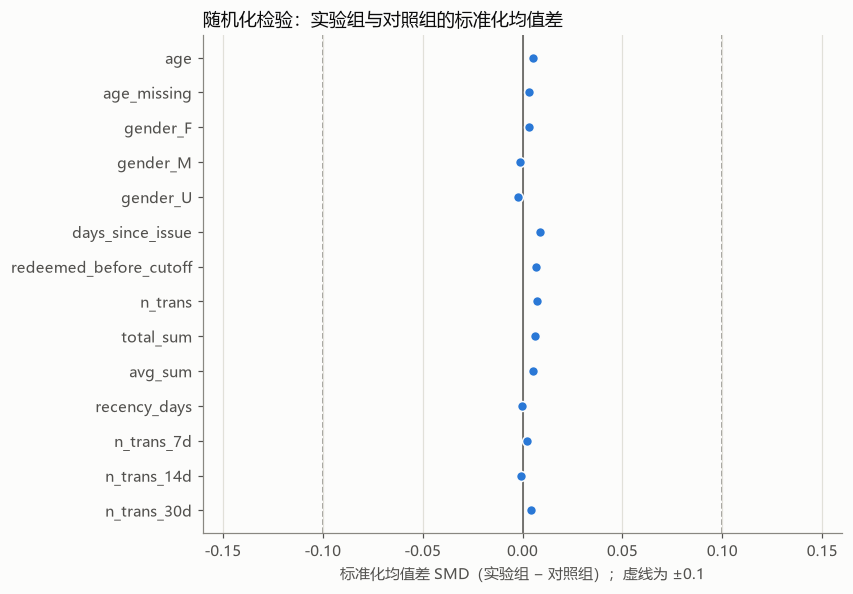

In [6]:
fig, ax = smd_plot(bal["smd"], threshold=0.1, title="随机化检验：实验组与对照组的标准化均值差")
fig.savefig(RESULTS / "stage1_balance_smd.png")
plt.show()

## 1.6 平均处理效应（ATE）

两种算法应该给出相同的点估计：
- 手写的“两组均值之差 + 不合并方差的标准误”；
- 回归 `target ~ treatment`，用稳健标准误（相当于 Stata 的 `reg target treatment, robust`）。

In [7]:
ate = diff_in_means(y, t)
ate_reg = ols_ate(y, t)
result["ate"] = {"均值差（手写）": ate, "回归（HC1 稳健标准误）": ate_reg}
pd.DataFrame(result["ate"]).T

,实验组均值,对照组均值,ATE,标准误,置信区间下限,置信区间上限,z,p值,相对提升
均值差（手写）,0.636511,0.60328,0.033231,0.002169,0.028979,0.037483,15.31834,5.767195e-53,0.055084
回归（HC1 稳健标准误）,NaN,NaN,0.033231,0.002169,0.028979,0.037483,NaN,5.767195e-53,NaN


## 1.7 CUPED：用实验前的数据降低方差

**最简单的理解**：购买与否本身波动很大，但其中有一部分可以用“这个人平时买得勤不勤”来预测。把这部分可以预测的波动先减掉，剩下的噪声就小了，同样的样本量就能更精确地估计效应。

- 公式：y_cuped = y − θ × (x − x 的均值)，θ = cov(y, x) / var(x)。
- 只要 x 发生在实验之前（和分组无关），调整后估计仍然无偏；方差缩减的比例约等于 y 和 x 相关系数的平方。
- 和计量的关系：单个协变量的 CUPED，几乎等价于回归 `y ~ treatment + x`（协方差分析，ANCOVA）。

下面比较几个候选的实验前指标，再把多个指标一起放进回归。

In [8]:
candidates = ["n_trans_7d", "n_trans_14d", "n_trans_30d", "n_trans", "recency_days", "total_sum"]
rows = {}
for c in candidates:
    r = cuped(y, t, df[c].to_numpy())
    rows[c] = {"theta": r["theta"], "方差缩减比例": r["方差缩减比例"], "相关系数平方": r["相关系数平方"],
               "ATE": r["ATE"], "标准误": r["标准误"], "置信区间下限": r["置信区间下限"], "置信区间上限": r["置信区间上限"]}
cuped_table = pd.DataFrame(rows).T.sort_values("方差缩减比例", ascending=False)
best_cov = cuped_table.index[0]
multi_cols = ["n_trans_7d", "n_trans_14d", "n_trans_30d", "n_trans", "recency_days", "total_sum", "avg_sum"]
ancova_single = ols_ate(y, t, df[[best_cov]].to_numpy())
ancova_multi = ols_ate(y, t, df[multi_cols].to_numpy())
cuped_table.to_csv(RESULTS / "stage1_cuped_candidates.csv", encoding="utf-8-sig")
display(cuped_table.round(5))
pd.DataFrame({"不调整": ate_reg, f"CUPED（{best_cov}）": rows[best_cov],
              f"回归调整（{best_cov}）": ancova_single, "回归调整（7 个实验前指标）": ancova_multi}).T[
    ["ATE", "标准误", "置信区间下限", "置信区间上限"]].round(5)

,theta,方差缩减比例,相关系数平方,ATE,标准误,置信区间下限,置信区间上限
n_trans,0.00976,0.12717,0.12717,0.03197,0.00203,0.02799,0.03594
n_trans_30d,0.03075,0.12376,0.12376,0.03254,0.00203,0.02856,0.03652
n_trans_14d,0.05526,0.11042,0.11042,0.03335,0.00205,0.02934,0.03736
recency_days,-0.02754,0.10339,0.10339,0.03320,0.00205,0.02917,0.03723
n_trans_7d,0.08794,0.09603,0.09603,0.03287,0.00206,0.02882,0.03691
total_sum,0.00001,0.06091,0.06091,0.03247,0.00210,0.02835,0.03659


,ATE,标准误,置信区间下限,置信区间上限
不调整,0.03323,0.00217,0.02898,0.03748
CUPED（n_trans）,0.03197,0.00203,0.02799,0.03594
回归调整（n_trans）,0.03197,0.00203,0.02799,0.03594
回归调整（7 个实验前指标）,0.03241,0.00198,0.02854,0.03629


### 反面例子：如果用了受处理影响的变量

“首次兑换积分”有一部分发生在截止日之后，也就是短信发出之后。先看这个“截止日后才首次兑换”的比例在两组之间是否不同：如果不同，说明它受到了短信的影响，就是一个**坏控制变量**（bad control）。把它当作 CUPED 的协变量，会把真实效应“调掉”一部分。

In [9]:
after = (df.join(clients.set_index("client_id")["first_redeem_date"])["first_redeem_date"] >= cutoff).astype(int)
bad = {
    "截止日后首次兑换的比例·实验组": float(after[t == 1].mean()),
    "截止日后首次兑换的比例·对照组": float(after[t == 0].mean()),
    "两组差异": diff_in_means(after.to_numpy(), t),
}
bad_cuped = cuped(y, t, after.to_numpy())
bad["用它做 CUPED 后的 ATE"] = bad_cuped["ATE"]
bad["不调整的 ATE"] = ate["ATE"]
result["bad_control_demo"] = bad
bad

{'截止日后首次兑换的比例·实验组': 0.11492183514867825,
 '截止日后首次兑换的比例·对照组': 0.11103559935237563,
 '两组差异': {'实验组均值': 0.11492183514867825,
  '对照组均值': 0.11103559935237563,
  'ATE': 0.003886235796302623,
  '标准误': 0.0014155762722288727,
  '置信区间下限': 0.0011117572853645654,
  '置信区间上限': 0.006660714307240681,
  'z': 2.7453383279613846,
  'p值': 0.006044854340068497,
  '相对提升': 0.03499990830841115},
 '用它做 CUPED 后的 ATE': 0.0333065403980104,
 '不调整的 ATE': 0.03323083953462003}

## 1.8 最小可检测效应（MDE）

在 5% 显著性水平、80% 检验功效下，当前样本量能可靠检测出的最小效应有多大。CUPED 让标准误变小，MDE 也随之变小；“等效样本量倍数” = 1 ÷ (1 − 方差缩减比例)，表示不做 CUPED 要多大的样本才能达到同样的精度。

In [10]:
se_raw = ate["标准误"]
se_cuped = rows[best_cov]["标准误"]
se_multi = ancova_multi["标准误"]
mde_table = {
    "不调整": {"标准误": se_raw, "MDE（百分点）": mde(se_raw) * 100},
    f"CUPED（{best_cov}）": {"标准误": se_cuped, "MDE（百分点）": mde(se_cuped) * 100,
                           "等效样本量倍数": 1 / (1 - rows[best_cov]["方差缩减比例"])},
    "回归调整（7 个实验前指标）": {"标准误": se_multi, "MDE（百分点）": mde(se_multi) * 100,
                          "等效样本量倍数": (se_raw / se_multi) ** 2},
}
result["mde"] = mde_table
result["cuped_best"] = {"协变量": best_cov, **rows[best_cov]}
result["ancova_multi"] = {"协变量": multi_cols, **ancova_multi}
pd.DataFrame(mde_table).T.round(4)

,标准误,MDE（百分点）,等效样本量倍数
不调整,0.0022,0.6078,NaN
CUPED（n_trans）,0.0020,0.5678,1.1457
回归调整（7 个实验前指标）,0.0020,0.5534,1.2063


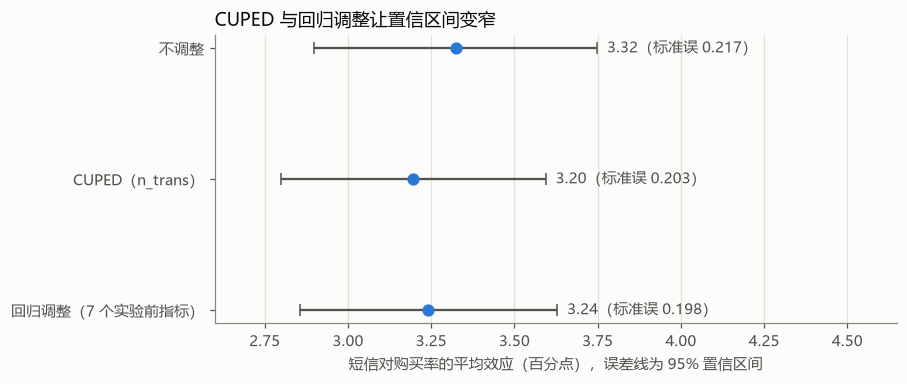

In [11]:
methods = ["不调整", f"CUPED（{best_cov}）", "回归调整（7 个实验前指标）"]
est = [ate_reg, rows[best_cov], ancova_multi]
fig, ax = plt.subplots(figsize=(8, 3.4))
yy = np.arange(len(methods))[::-1]
for i, (m, e) in enumerate(zip(methods, est)):
    ax.errorbar(e["ATE"] * 100, yy[i], xerr=[[ (e["ATE"] - e["置信区间下限"]) * 100], [(e["置信区间上限"] - e["ATE"]) * 100]],
                fmt="o", color=SERIES[0], ecolor=INK_SECONDARY, capsize=4, markersize=7)
    ax.text(e["置信区间上限"] * 100 + 0.03, yy[i], f"{e['ATE'] * 100:.2f}（标准误 {e['标准误'] * 100:.3f}）",
            va="center", fontsize=10, color=INK_SECONDARY)
ax.set_yticks(yy, methods)
ax.set_xlabel("短信对购买率的平均效应（百分点），误差线为 95% 置信区间")
ax.set_title("CUPED 与回归调整让置信区间变窄", loc="left")
ax.set_xlim(left=min(e["置信区间下限"] for e in est) * 100 - 0.2, right=max(e["置信区间上限"] for e in est) * 100 + 0.9)
ax.grid(axis="y", visible=False)
fig.savefig(RESULTS / "stage1_ate_cuped.png")
plt.show()

## 1.9 保存结果

In [12]:
def to_json(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)

(RESULTS / "stage1_ab_test.json").write_text(json.dumps(result, ensure_ascii=False, indent=2, default=to_json), encoding="utf-8")
print("已保存：stage1_ab_test.json、stage1_balance.csv、stage1_balance_smd.png、stage1_cuped_candidates.csv、stage1_ate_cuped.png")

已保存：stage1_ab_test.json、stage1_balance.csv、stage1_balance_smd.png、stage1_cuped_candidates.csv、stage1_ate_cuped.png
